In [1]:
import polars as pl

In [2]:
flights = pl.scan_parquet("../data/flights.parquet")
airlines = pl.scan_parquet("../data/airlines.parquet")
airports = pl.scan_parquet("../data/airports.parquet")

In [29]:
#ilość lotów z danych lotnisk
#TODO no of flights per airport on map
def filter_airports(flights_f, airports_f, min_count, states):
    airlines_counts = (flights_f
                       .join(airports_f, left_on='ORIGIN_AIRPORT', right_on='IATA_CODE', how='inner')
                       .group_by('AIRPORT', 'LATITUDE', 'LONGITUDE', 'STATE')
                       .agg(pl.len().alias('COUNT'))
                       .filter(pl.col('COUNT') >= min_count)
                       )
    if states != 'Wszystkie':
        airlines_counts = (airlines_counts
                           .filter(pl.col('STATE').is_in(states)))

    return airlines_counts.collect()


def outgoing_flights_plot(data_frame):
    import plotly.express as px

    fig = px.scatter_map(
        data_frame,
        lat='LATITUDE',
        lon='LONGITUDE',
        size='COUNT',
        color='COUNT',
        hover_name='AIRPORT',
        custom_data=['COUNT'],
        color_continuous_scale='Turbo',
        size_max=40,
        zoom=3,
        title='Amount of outgoing flights',
        map_style="open-street-map",
        #    map_style="carto-darkmatter"
        #map_center={"lat": 39.5, "lon": -98.35},
    )
    fig.update_traces(
        hovertemplate="<b>%{hovertext}</b><br>Flights: %{customdata[0]}<extra></extra>"
    )

    #fig.show(renderer="browser")
    #fig.show()
    fig.write_html("outgoing_flights_plot.html", auto_open=True)


outgoing_flights_plot(filter_airports(flights, airports, 0, ['FL']))

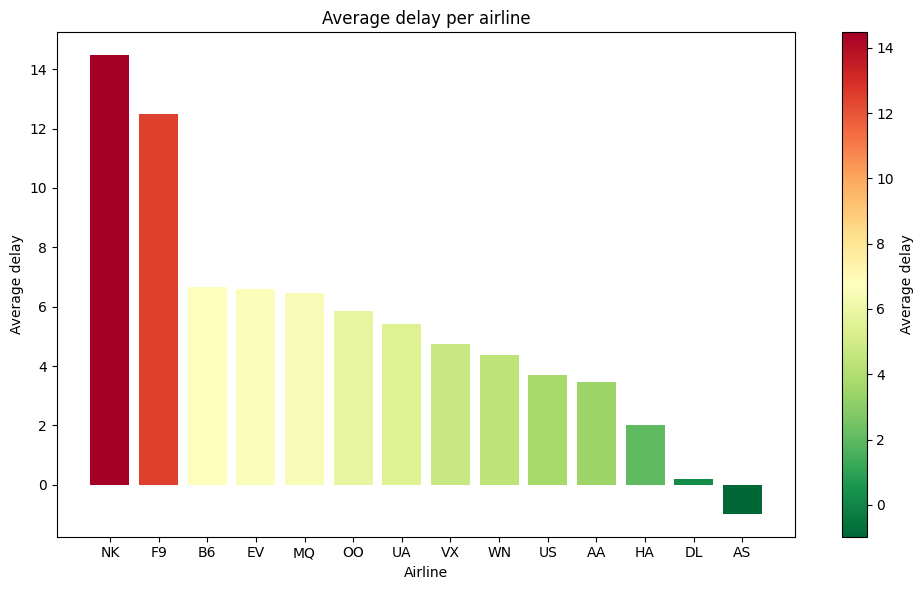

In [13]:
#średni delay per linia
#TODO Average delay per airline plot
def filter_airlines_with_avg_delay(flights_f, airlines_f, min_delay, max_delay, airlines_list):
    airlines_counts = (flights_f
                       .join(airlines_f, left_on='AIRLINE', right_on='IATA_CODE', how='inner')
                       .group_by('AIRLINE')
                       .agg(pl.mean('ARRIVAL_DELAY').alias('MEAN'))
                       .filter(pl.col('MEAN') >= min_delay, max_delay >= pl.col('MEAN'))
                       .sort('MEAN', descending=True)
                       )
    if airlines_list != 'Wszystkie':
        airlines_counts = (airlines_counts
                           .filter(pl.col('AIRLINE').is_in(airlines_list)))
    return airlines_counts.collect()


def average_airlines_delay_plot(data_frame):
    import matplotlib.pyplot as plt
    import matplotlib.colors as mcolors
    import matplotlib.cm as cm

    airlines_values = data_frame.get_column('AIRLINE').to_list()
    delay_values = data_frame.get_column('MEAN').to_list()

    norm = mcolors.Normalize(
        vmin=min(delay_values),
        vmax=max(delay_values)
    )

    colormap = plt.get_cmap('RdYlGn_r')
    colors = [colormap(norm(value)) for value in delay_values]

    fig, ax = plt.subplots(figsize=(10, 6))
    ax.bar(airlines_values,
           delay_values,
           color=colors
           )

    ax.set_xlabel('Airline')
    ax.set_ylabel('Average delay')
    ax.set_title('Average delay per airline')

    scalar_map = cm.ScalarMappable(norm=norm, cmap=colormap)
    scalar_map.set_array([])

    fig.colorbar(
        scalar_map,
        ax=ax,
        label='Average delay'
    )

    plt.tight_layout()
    plt.show()


average_airlines_delay_plot(filter_airlines_with_avg_delay(flights, airlines, -1000, 1000, 'Wszystkie'))

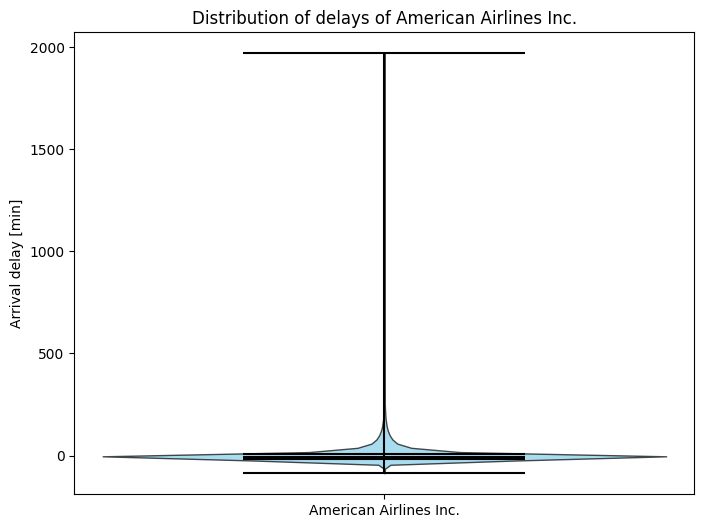

In [12]:
#distrybucja delayow dla lini
#TODO distribution of delays per airline
def filter_airlines_with_delay(flights_f, airlines_f, airline):
    filtered_airline = (flights_f
                        .join(airlines_f.rename({'AIRLINE': 'AIRLINE_NAME'}), left_on='AIRLINE', right_on='IATA_CODE',
                              how='inner')
                        .filter(pl.col('AIRLINE') == airline)
                        .select('AIRLINE', 'ARRIVAL_DELAY', 'AIRLINE_NAME')
                        .drop_nulls()
                        ).collect()
    return filtered_airline


def airlines_delay_distribution_plot(data_frame):
    import matplotlib.pyplot as plt

    AIRLINE_NAME = data_frame['AIRLINE_NAME'].to_list()[0]
    ARRIVAL_DELAY = data_frame['ARRIVAL_DELAY'].to_list()

    fig, ax = plt.subplots(figsize=(8, 6))

    violins = ax.violinplot(
        [ARRIVAL_DELAY],
        showmeans=False,
        showextrema=True,
        showmedians=True,
        quantiles=[[0.25, 0.75]],
        bw_method='silverman'
    )

    body = violins['bodies'][0]
    body.set_facecolor('skyblue')
    body.set_edgecolor('black')
    body.set_alpha(0.7)

    for partname in ('cbars', 'cmins', 'cmaxes', 'cmedians', 'cquantiles'):
        if partname in violins:
            violins[partname].set_edgecolor('black')
            violins[partname].set_linewidth(1.5)

    ax.set_xticks([1])
    ax.set_xticklabels([AIRLINE_NAME])
    ax.set_ylabel('Arrival delay [min]')
    ax.set_title(f'Distribution of delays of {AIRLINE_NAME}')

    plt.show()


#filter_airlines_with_delay_and_cancellation('AA').collect()
airlines_delay_distribution_plot(filter_airlines_with_delay(flights, airlines, 'AA'))

In [11]:
#rozbicie opóźnień wg typów dla lotnisk
#TODO airport_delays_divided_by_occurrence_plot
def filter_airports_with_divided_delay(flights_f, airports_f, airport):
    return (flights_f
    .join(airports_f, left_on='ORIGIN_AIRPORT', right_on='IATA_CODE', how='inner')
    .filter(pl.col(
        'ORIGIN_AIRPORT') == airport)  #TODO zmienic na airport a nie origin_airport zeby po nazwie filtrowac, zrobione tak zeby bylo latwiej
    .group_by('AIRPORT')
    .agg(
        pl.sum('AIR_SYSTEM_DELAY').fill_null(0),
        pl.sum('SECURITY_DELAY').fill_null(0),
        pl.sum('AIRLINE_DELAY').fill_null(0),
        pl.sum('LATE_AIRCRAFT_DELAY').fill_null(0),
        pl.sum('WEATHER_DELAY').fill_null(0)
    )
    ).with_columns(
        pl.sum_horizontal("AIR_SYSTEM_DELAY", "SECURITY_DELAY", "AIRLINE_DELAY", "LATE_AIRCRAFT_DELAY",
                          "WEATHER_DELAY").alias("SUM")).collect()


#filter_airports_with_divided_delay('ABE').collect()

def airport_delays_divided_by_occurrence_plot(data_frame):
    import plotly.graph_objects as go
    from plotly.subplots import make_subplots

    columns = ["AIR_SYSTEM_DELAY", "SECURITY_DELAY", "AIRLINE_DELAY", "LATE_AIRCRAFT_DELAY", "WEATHER_DELAY"]
    colours = ["#87A987", "#B76E79", "#1D2A44", "#E8D8C8", "#E3A857"]

    dane = [{
        "percent": round(data_frame[col].item() / data_frame["SUM"].item() * 100.0, 1) if data_frame[
                                                                                              "SUM"].item() != 0 else 0,
        "colour": color,
        "label": "INFODATA"
    } for col, color in zip(columns, colours)]

    fig = make_subplots(
        rows=1, cols=5,
        specs=[[{"type": "domain"}, {"type": "domain"}, {"type": "domain"}, {"type": "domain"},
                {"type": "domain"}]],
        subplot_titles=[name.replace("_DELAY", "").replace("_", " ") for name in columns]
    )
    domains = [fig.get_subplot(1, i + 1) for i in range(len(columns))]

    for i, (d, domain) in enumerate(zip(dane, domains)):
        x_center = (domain.x[0] + domain.x[1]) / 2
        y_center = (domain.y[0] + domain.y[1]) / 2
        fig.add_trace(
            go.Pie(
                values=[d["percent"], 100 - d["percent"]],
                hole=0.65,
                marker_colors=[d["colour"], "#E0E0E0"],
                textinfo="none",
                showlegend=False,

            ),
            row=1, col=i + 1
        )

        fig.add_annotation(
            text=f"<b>{d['percent']}%</b>",
            xref='paper', yref='paper',
            x=x_center,
            y=y_center,
            font=dict(
                size=16,
                color=d["colour"]
            ),
            xanchor="center",
            yanchor="middle",
            showarrow=False
        )

    for annotation in fig['layout']['annotations']:
        if "<b>" not in annotation['text']:
            annotation['y'] = -0.1
            annotation['yanchor'] = 'top'

    fig.update_layout(
        title=dict(text="<b>DELAYS INFOGRAPHIC</b>", x=0.5),
        height=350,
        paper_bgcolor="white",
        margin=dict(
            l=20,
            r=20,
            t=60,
            b=80
        )
    )

    #fig.show(renderer="browser")
    fig.show()


airport_delays_divided_by_occurrence_plot(filter_airports_with_divided_delay(flights, airports, 'ABE'))


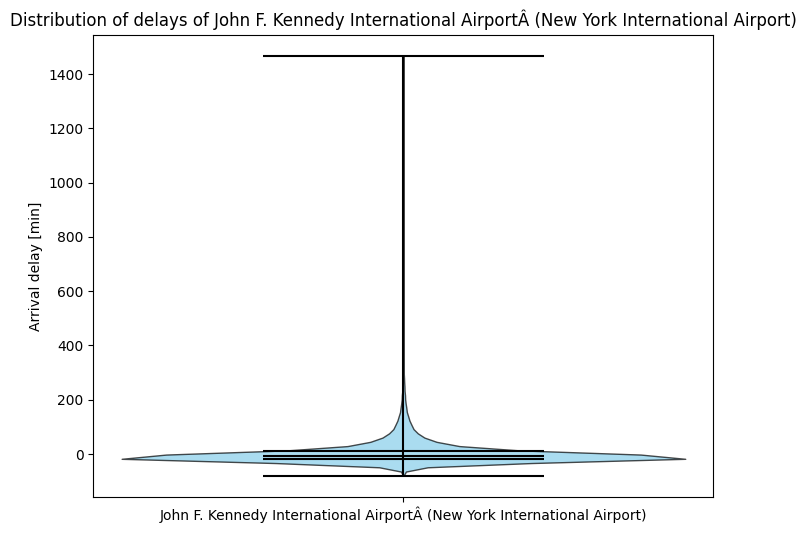

In [10]:
#distrybucja delayow dla lotniska
#TODO distribution of delays per airline
def filter_airport_with_delay(flights_f, airports_f, airport):
    filtered_airline = (flights_f
                        .join(airports_f, left_on='ORIGIN_AIRPORT', right_on='IATA_CODE', how='inner')
                        .filter(pl.col(
        'ORIGIN_AIRPORT') == airport
                                )
                        .select('ORIGIN_AIRPORT', 'ARRIVAL_DELAY', 'AIRPORT')
                        .drop_nulls()
                        )
    return filtered_airline.collect()


def airport_delay_distribution_plot(data_frame):
    import matplotlib.pyplot as plt

    AIRLINE_NAME = data_frame['AIRPORT'].to_list()[0]
    ARRIVAL_DELAY = data_frame['ARRIVAL_DELAY'].to_list()

    fig, ax = plt.subplots(figsize=(8, 6))

    violins = ax.violinplot(
        [ARRIVAL_DELAY],
        showmeans=False,
        showextrema=True,
        showmedians=True,
        quantiles=[[0.25, 0.75]],
        bw_method='silverman'
    )

    body = violins['bodies'][0]
    body.set_facecolor('skyblue')
    body.set_edgecolor('black')
    body.set_alpha(0.7)

    for partname in ('cbars', 'cmins', 'cmaxes', 'cmedians', 'cquantiles'):
        if partname in violins:
            violins[partname].set_edgecolor('black')
            violins[partname].set_linewidth(1.5)

    ax.set_xticks([1])
    ax.set_xticklabels([AIRLINE_NAME])
    ax.set_ylabel('Arrival delay [min]')
    ax.set_title(f'Distribution of delays of {AIRLINE_NAME}')

    plt.show()


#filter_airlines_with_delay_and_cancellation('AA').collect()
airport_delay_distribution_plot(filter_airport_with_delay(flights, airports, 'JFK'))

In [15]:
#okragly wykres z opoznieniami wg miesiaca
#TODO jakies wykresy związane z sezonowością opznien i cancelacji wg miesiaca
def filter_delays_per_seasons(lazy_frame, start_month=1, end_month=12,
                              occurrence="Delay"):  #zrobic zeby mozna było wybierac albo cancele albo delay
    filtered_frame = (lazy_frame
                      .filter(
        (pl.col("MONTH").cast(pl.String).cast(pl.Int32) >= start_month) & (
                pl.col("MONTH").cast(pl.String).cast(pl.Int32) <= end_month)
    )
                      .with_columns(pl.col("MONTH").cast(pl.String).cast(pl.Int32))
                      )

    if occurrence == "Delay":
        return (filtered_frame
                .group_by("MONTH")
                .agg(
            pl.col("ARRIVAL_DELAY").filter(pl.col("ARRIVAL_DELAY") > 0).count().alias("DELAY_COUNT"),
            pl.col("ARRIVAL_DELAY").filter(pl.col("ARRIVAL_DELAY") > 0).sum().alias("DELAY_SUM"),
            pl.len().alias("AMOUNT_OF_FLIGHTS")
        )
                .with_columns(
            (pl.col("DELAY_COUNT") / pl.col("AMOUNT_OF_FLIGHTS") * 100.0).round(1).alias("DELAY_PCT"),
            (pl.col("DELAY_SUM") / pl.col("AMOUNT_OF_FLIGHTS") * 100.0).round(1).alias("AVG_DELAY")
        )
                .drop('DELAY_COUNT', 'DELAY_SUM', 'AMOUNT_OF_FLIGHTS')
                .sort("MONTH")
                ).collect()
    else:
        return (filtered_frame
                .group_by("MONTH")
                .agg(
            pl.col("CANCELLED").filter(pl.col("CANCELLED") > 0).count().alias("CANCELLED_COUNT"),
            pl.len().alias("AMOUNT_OF_FLIGHTS")
        )
                .with_columns(
            (pl.col("CANCELLED_COUNT") / pl.col("AMOUNT_OF_FLIGHTS") * 100.0).round(1).alias("CANCELLED_PCT"),
        )
                .drop('CANCELLED_COUNT', 'AMOUNT_OF_FLIGHTS')
                .sort("MONTH")
                ).collect()


def convert_number_to_months(numbers):
    mapping = {
        1: "January",
        2: "February",
        3: "March",
        4: "April",
        5: "May",
        6: "June",
        7: "July",
        8: "August",
        9: "September",
        10: "October",
        11: "November",
        12: "December"
    }

    months = [mapping.get(number) for number in numbers]

    return months


def delay_and_cancel_seasonality_plot(data_frame):
    import plotly
    import plotly.graph_objects as go

    MONTH = data_frame['MONTH'].to_list()
    #MONTH = MONTH + [MONTH[0]]
    MONTH = convert_number_to_months(MONTH)

    if 'CANCELLED_PCT' in data_frame.columns:
        CANCELLED_PCT = data_frame['CANCELLED_PCT'].to_list()
        #CANCELLED_PCT = CANCELLED_PCT + [CANCELLED_PCT[0]]

        fig = go.Figure(
            go.Barpolar(
                r=CANCELLED_PCT,
                theta=MONTH,
                marker=dict(
                    color=CANCELLED_PCT,
                    colorscale="RdYlGn_r",
                    showscale=True,
                    cmin=min(CANCELLED_PCT),
                    cmax=max(CANCELLED_PCT)
                )
            ))

        fig.update_layout(
            title=dict(
                text="Percentage of cancelled flights",
                x=0.5,
                xanchor="center"
            )
        )

    else:
        DELAY_PCT = data_frame['DELAY_PCT'].to_list()
        AVG_DELAY = data_frame['AVG_DELAY'].to_list()
        #DELAY_PCT = DELAY_PCT + [DELAY_PCT[0]]
        #AVG_DELAY = AVG_DELAY + [AVG_DELAY[0]]

        fig = plotly.subplots.make_subplots(
            rows=1, cols=2,
            specs=[[{"type": "polar"}, {"type": "polar"}]],
            subplot_titles=["Percentage of delayed flights", "Average delay per month"]
        )

        fig.add_trace(
            go.Barpolar(
                r=DELAY_PCT,
                theta=MONTH,
                marker=dict(
                    color=DELAY_PCT,
                    colorscale="RdYlGn_r",
                    showscale=True,
                    cmin=min(DELAY_PCT),
                    cmax=max(DELAY_PCT),
                    colorbar=dict(x=-0.1)
                )
            ),
            row=1, col=1
        )

        fig.add_trace(
            go.Barpolar(
                r=AVG_DELAY,
                theta=MONTH,
                marker=dict(
                    color=AVG_DELAY,
                    colorscale="RdYlGn_r",
                    showscale=True,
                    cmin=min(AVG_DELAY),
                    cmax=max(AVG_DELAY)
                )
            ),
            row=1, col=2
        )

        fig.update_layout(
            polar1=dict(radialaxis=dict(range=[0, max(DELAY_PCT) * 1.2])),
            polar2=dict(radialaxis=dict(range=[0, max(AVG_DELAY) * 1.2]))
        )

    fig.update_layout(showlegend=False)
    fig.update_annotations(yshift=20)
    fig.write_html("sezonowosc.html", auto_open=True)
    #fig.show()


delay_and_cancel_seasonality_plot(filter_delays_per_seasons(flights, occurrence="Delay"))

In [16]:
#heatmapa opoznien per dow i month
#TODO delays per day fo week and month with density heatmap

def get_months_mapping():
    mapping = {
        1: "January",
        2: "February",
        3: "March",
        4: "April",
        5: "May",
        6: "June",
        7: "July",
        8: "August",
        9: "September",
        10: "October",
        11: "November",
        12: "December"
    }
    return mapping


def get_dow_mapping():
    mapping = {
        1: "Monday",
        2: "Tuesday",
        3: "Wednesday",
        4: "Thursday",
        5: "Friday",
        6: "Saturday",
        7: "Sunday",
    }
    return mapping


def delays_or_cancellation_w_month_and_dow(lazy_frame,
                                           occurrence="Delay"):  #zrobic zeby mozna było wybierac albo cancele albo delay
    filtered_frame = (lazy_frame
    .with_columns(
        pl.col("MONTH").cast(pl.String).cast(pl.Int32).replace_strict(get_months_mapping(), default=None),
        pl.col("DAY_OF_WEEK").cast(pl.String).cast(pl.Int32).replace_strict(get_dow_mapping(), default=None))
    )

    if occurrence == "Delay":
        return (filtered_frame
                .select("MONTH", "DAY_OF_WEEK", "ARRIVAL_DELAY")
                ).collect()
    else:
        return (filtered_frame
                .select("MONTH", "DAY_OF_WEEK", "CANCELLED")
                ).collect()


def heatmap_plot(data_frame):
    import plotly.express as px

    dow_order = list(get_dow_mapping().values())
    month_order = list(get_months_mapping().values())

    month_order.reverse()

    if 'CANCELLED' in data_frame.columns:
        col_name = 'CANCELLED'
        title = 'Średni wskaźnik odwołań lotów (Dzień tyg. vs Miesiąc)'
        palette = 'Reds'
        text_auto = '.3f'
    else:
        col_name = 'ARRIVAL_DELAY'
        title = 'Średnie opóźnienie przylotu w minutach (Dzień tyg. vs Miesiąc)'
        palette = 'YlOrRd'
        text_auto = '.1f'

    fig = px.density_heatmap(
        data_frame,
        x='DAY_OF_WEEK',
        y='MONTH',
        z=f'{col_name}',
        histfunc='avg',

        category_orders={
            'DAY_OF_WEEK': dow_order,
            'MONTH': month_order
        },
        color_continuous_scale=palette,
        text_auto=text_auto,
        title=title,
        labels={
            'DAY_OF_WEEK': 'Day of week',
            'MONTH': 'Month',
            #col_name:'Delay'
        }
    )

    fig.update_layout(
        xaxis_title=None,
        yaxis_title=None,
        height=600,
        margin=dict(
            t=50,
            l=100,
            r=20,
            b=20
        )
    )

    fig.write_html("heatmap_plot.html", auto_open=True)


heatmap_plot(delays_or_cancellation_w_month_and_dow(flights, "Deslay"))

In [18]:
#Wykres tras na którym można wybierac konkretne lotnisko lub top x polączeń
#TODO jakies wykresy wizualizujące np polączenia
def group_airport_pairs(flights_f, airports_f, mode='Top', num=10, airport='JFK'):
    pairs = (flights_f
             .with_columns(
        AIRPORT_1=pl.when(pl.col('ORIGIN_AIRPORT') < pl.col('DESTINATION_AIRPORT'))
        .then(pl.col('ORIGIN_AIRPORT'))
        .otherwise(pl.col('DESTINATION_AIRPORT')),

        AIRPORT_2=pl.when(pl.col('ORIGIN_AIRPORT') < pl.col('DESTINATION_AIRPORT'))
        .then(pl.col('DESTINATION_AIRPORT'))
        .otherwise(pl.col('ORIGIN_AIRPORT')),
    )
             .group_by('AIRPORT_1', 'AIRPORT_2')
             .agg(pl.len().alias('COUNT'))

             .join(airports_f.select(['IATA_CODE', 'AIRPORT', 'LATITUDE', 'LONGITUDE']), left_on='AIRPORT_1',
                   right_on='IATA_CODE',
                   how='inner')
             .rename({
        'LATITUDE': 'LAT_1',
        'LONGITUDE': 'LON_1',
        'AIRPORT': 'AIRPORT_1_NAME'}
    )
             .join(airports_f.select(['IATA_CODE', 'AIRPORT', 'LATITUDE', 'LONGITUDE']), left_on='AIRPORT_2',
                   right_on='IATA_CODE',
                   how='inner')
             .rename({
        'LATITUDE': 'LAT_2',
        'LONGITUDE': 'LON_2',
        'AIRPORT': 'AIRPORT_2_NAME'})
             .sort('COUNT', descending=True)
             )

    if mode == 'Top':
        pairs = pairs.head(num)
    else:
        pairs = pairs.filter((pl.col('AIRPORT_1') == airport) | (pl.col('AIRPORT_2') == airport))
    return pairs.collect()


def trails_plot(data_frame):
    import plotly.graph_objects as go

    fig = go.Figure()
    max_count = data_frame['COUNT'].max()

    for row in data_frame.iter_rows(named=True):
        thickness = (row['COUNT'] / max_count) * 4.5 + 0.5

        fig.add_trace(go.Scattergeo(
            lon=[row['LON_1'], row['LON_2']],
            lat=[row['LAT_1'], row['LAT_2']],
            mode='lines',
            line=dict(
                width=thickness,
                color='#00BFFF'
            ),
            opacity=0.6,

        ))

        fig.add_trace(go.Scattergeo(
            lon=[(row['LON_1'] + row['LON_2']) / 2],
            lat=[(row['LAT_1'] + row['LAT_2']) / 2],
            mode='markers',
            marker=dict(size=10, opacity=0),
            name=f"{row['AIRPORT_1']} <-> {row['AIRPORT_2']}",
            hoverinfo="name+text",
            text=f"Amount of flights in both directions: {row['COUNT']}",
            showlegend=False
        ))

    lon_airports = data_frame['LON_1'].to_list() + data_frame['LON_2'].to_list()
    lat_airports = data_frame['LAT_1'].to_list() + data_frame['LAT_2'].to_list()
    name_airports = data_frame['AIRPORT_1_NAME'].to_list() + data_frame['AIRPORT_2_NAME'].to_list()

    fig.add_trace(go.Scattergeo(
        lon=lon_airports,
        lat=lat_airports,
        hoverinfo='text',
        text=name_airports,
        mode='markers',
        marker=dict(
            size=5,
            color='#F92672',
            line=dict(
                width=1,
                color='white'
            )
        ),
        showlegend=False
    ))
    fig.update_layout(
        title_text='Air connections between airports',
        title_x=0.5,
        geo=dict(
            scope='north america',
            #projection_type='albers usa',
            showland=True,
            landcolor='rgb(243,243,243)',
            countrycolor='rgb(204,204,204)'
        ),
        margin=dict(
            l=0,
            r=0,
            t=60,
            b=0
        ),
        showlegend=False,
        #    fitbounds="locations"
    )
    fig.write_html("mapa_polaczen_dwukierunkowa.html", auto_open=True, include_mathjax=False)


trails_plot(group_airport_pairs(flights, airports, num=10))

In [19]:
#spoznienia dla danych par
#TODO najwiecej spózniej dla danych par, nie tylko dla liniii
def filter_top_10_pairs_with_avg_delay(flights_f, airports_f, min_dep_delay, max_dep_delay, min_arr_delay,
                                       max_arr_delay,
                                       airport='JFK'):
    pairs = (flights_f
             .with_columns(
        AIRPORT_1=pl.when(pl.col('ORIGIN_AIRPORT') < pl.col('DESTINATION_AIRPORT'))
        .then(pl.col('ORIGIN_AIRPORT'))
        .otherwise(pl.col('DESTINATION_AIRPORT')),

        AIRPORT_2=pl.when(pl.col('ORIGIN_AIRPORT') < pl.col('DESTINATION_AIRPORT'))
        .then(pl.col('DESTINATION_AIRPORT'))
        .otherwise(pl.col('ORIGIN_AIRPORT')),
    )
             .group_by('AIRPORT_1', 'AIRPORT_2')
             .agg(pl.median("ARRIVAL_DELAY").alias("MEDIAN_ARRIVAL_DELAY"),
                  pl.median("DEPARTURE_DELAY").alias("MEDIAN_DEPARTURE_DELAY")
                  )

             .join(airports_f.select(['IATA_CODE', 'AIRPORT']), left_on='AIRPORT_1',
                   right_on='IATA_CODE',
                   how='inner')
             .rename({
        'AIRPORT': 'AIRPORT_1_NAME'}
    )
             .join(airports_f.select(['IATA_CODE', 'AIRPORT']), left_on='AIRPORT_2',
                   right_on='IATA_CODE',
                   how='inner')
             .rename({
        'AIRPORT': 'AIRPORT_2_NAME'}
    )
             .filter(
        pl.col('MEDIAN_DEPARTURE_DELAY') >= min_dep_delay,
        max_dep_delay >= pl.col('MEDIAN_DEPARTURE_DELAY'),
        pl.col('MEDIAN_ARRIVAL_DELAY') >= min_arr_delay,
        max_arr_delay >= pl.col('MEDIAN_ARRIVAL_DELAY'),
    )
             .filter((pl.col('AIRPORT_1') == airport) | (pl.col('AIRPORT_2') == airport))
             .with_columns(
        PAIR_NAME=pl.concat_str(['AIRPORT_1', pl.lit(' ↔ '), 'AIRPORT_2'])
    )
             .sort('MEDIAN_ARRIVAL_DELAY', descending=True)
             .head(10)
             )

    return pairs.collect()


def average_pairs_delay_plot(data_frame):
    import plotly.graph_objects as go

    MEDIAN_DEPARTURE_DELAY = data_frame['MEDIAN_DEPARTURE_DELAY'].to_list()
    MEDIAN_ARRIVAL_DELAY = data_frame['MEDIAN_ARRIVAL_DELAY'].to_list()
    PAIR_NAME = data_frame['PAIR_NAME'].to_list()
    AIRPORT_NAME = (data_frame
                    .group_by('AIRPORT_1', 'AIRPORT_1_NAME')
                    .agg(pl.len().alias('COUNT'))
                    .sort('COUNT', descending=True)
                    .head(1)
                    .select('AIRPORT_1_NAME')
                    .item())

    fig = go.Figure(data=[
        go.Bar(
            x=PAIR_NAME,
            y=MEDIAN_ARRIVAL_DELAY,
            name="Arrival Delay Median",
            marker_color='#1f77b4',
        ),
        go.Bar(
            x=PAIR_NAME,
            y=MEDIAN_DEPARTURE_DELAY,
            name="Departure Delay Median",
            marker_color='#ff7f0e',
        ),
    ])

    fig.update_layout(
        barmode='group',
        title=f'Comparison of arrival and departure delays for {AIRPORT_NAME}',
        xaxis_title='Route',
        yaxis_title='Median of delay',
        hovermode='x unified'
    )

    fig.write_html("slupki_obok_siebie.html", auto_open=True, include_mathjax=False)


average_pairs_delay_plot(filter_top_10_pairs_with_avg_delay(flights, airports, -100, 100, -100, 10, "MSP"))

In [5]:
[str(i) for i in range(1,13)]

['1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12']

In [20]:
#jeden lot wizualizacja
#TODO jakaś wizualizacja lotu dla konkretntego lotu, taki dashboard z konkretnym lotem to już w shiny

def get_flight_info(flights_f, airports_f, flight_number, day, month, year, airline):
    pairs = (flights_f
    .filter(pl.col('FLIGHT_NUMBER').cast(pl.String).cast(pl.Int32) == flight_number,
            pl.col('YEAR').cast(pl.String).cast(pl.Int32) == year,
            pl.col('MONTH').cast(pl.String).cast(pl.Int32) == month,
            pl.col('DAY').cast(pl.String).cast(pl.Int32) == day,
            pl.col('AIRLINE').cast(pl.String) == airline)
    .with_columns(
        AIRPORT_1=pl.when(pl.col('ORIGIN_AIRPORT') < pl.col('DESTINATION_AIRPORT'))
        .then(pl.col('ORIGIN_AIRPORT'))
        .otherwise(pl.col('DESTINATION_AIRPORT')),

        AIRPORT_2=pl.when(pl.col('ORIGIN_AIRPORT') < pl.col('DESTINATION_AIRPORT'))
        .then(pl.col('DESTINATION_AIRPORT'))
        .otherwise(pl.col('ORIGIN_AIRPORT')),
    )
    .join(airports_f.select(['IATA_CODE', 'AIRPORT', 'LATITUDE', 'LONGITUDE']), left_on='AIRPORT_1',
          right_on='IATA_CODE',
          how='inner')
    .rename({
        'LATITUDE': 'LAT_1',
        'LONGITUDE': 'LON_1',
        'AIRPORT': 'AIRPORT_1_NAME'}
    )
    .join(airports_f.select(['IATA_CODE', 'AIRPORT', 'LATITUDE', 'LONGITUDE']), left_on='AIRPORT_2',
          right_on='IATA_CODE',
          how='inner')
    .rename({
        'LATITUDE': 'LAT_2',
        'LONGITUDE': 'LON_2',
        'AIRPORT': 'AIRPORT_2_NAME'})

    )

    return pairs.collect()


def flight_visualisation(data_frame):
    import plotly.graph_objects as go

    fig = go.Figure()
    for row in data_frame.iter_rows(named=True):
        thickness = 3

        fig.add_trace(go.Scattermap(
            lon=[row['LON_1'], row['LON_2']],
            lat=[row['LAT_1'], row['LAT_2']],
            mode='lines',
            line=dict(
                width=thickness,
                color='#00BFFF'
            ),
            opacity=0.6,

        ))

        fig.add_trace(go.Scattermap(
            lon=[(row['LON_1'] + row['LON_2']) / 2],
            lat=[(row['LAT_1'] + row['LAT_2']) / 2],
            mode='markers',
            marker=dict(size=10, opacity=0),
            name=f"{row['AIRPORT_1']} <-> {row['AIRPORT_2']}",
            hoverinfo="name+text",
            text=f"Flight between {row['AIRPORT_1_NAME']} and {row['AIRPORT_2_NAME']}",
            showlegend=False
        ))

    lon_airports = data_frame['LON_1'].to_list() + data_frame['LON_2'].to_list()
    lat_airports = data_frame['LAT_1'].to_list() + data_frame['LAT_2'].to_list()
    name_airports = data_frame['AIRPORT_1_NAME'].to_list() + data_frame['AIRPORT_2_NAME'].to_list()

    fig.add_trace(go.Scattermap(
        lon=lon_airports,
        lat=lat_airports,
        hoverinfo='text',
        text=name_airports,
        mode='markers+text',
        textposition='top right',
        marker=dict(size=12, color='#F92672'),
        showlegend=False
    ))

    padding = 3

    fig.update_layout(
        title_text='Flight visualisation',
        title_x=0.5,
        map=dict(
            style="carto-positron",
            center=dict(
                lat=(row['LAT_1'] + row['LAT_2']) / 2,
                lon=(row['LON_1'] + row['LON_2']) / 2
            ),
            zoom=4
        ),
        margin=dict(
            l=0,
            r=0,
            t=60,
            b=0
        ),
        showlegend=False,

    )
    fig.write_html("wizualizacja_polaczenia.html", auto_open=True, include_mathjax=False)


flight_visualisation(get_flight_info(flights, airports, 2336, 4, 1, 2015, "AA"))

In [ ]:
#TODO MoM dla delayu dla poszczegolnych linii lotniczych

In [ ]:
#TODO dodawac tabelki jakies top x lotnisk/linii/spoźnien etc

In [9]:
#TODO jakis wykres pokazujący ze z czasem delay spada?

In [ ]:
#TODO wizualizacja procent polaczen na

In [10]:
#TODO wykres związany z cancelacjami

In [12]:
#todo do modelu dodac flage czy poprzedni lot opoźniony czy coś

In [27]:
#Lista Lotnisk
def get_airlines_list(airlines_f):
    return airlines_f.select('IATA_CODE').unique().collect().get_column('IATA_CODE').sort().to_list()


get_airlines_list(airlines)

['AA',
 'AS',
 'B6',
 'DL',
 'EV',
 'F9',
 'HA',
 'MQ',
 'NK',
 'OO',
 'UA',
 'US',
 'VX',
 'WN']